import of the required librairies

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


reading from the giving dataset

In [2]:
data = pd.read_csv('/content/winequality-red.csv')

visualisation from the top 5

In [3]:
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
data.shape

(1599, 12)

classes of target value - > quality

In [5]:
set(data.quality) #see the numbers inside the quality

{3, 4, 5, 6, 7, 8}

the system will works based on the elements then to predict the quality of wine

description of the giving dataset

In [6]:
data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


to check the missing values

In [7]:
data.isnull().sum() # to checck the missing values

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


correclation matrix among all features inside the dataset


In [8]:
data.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

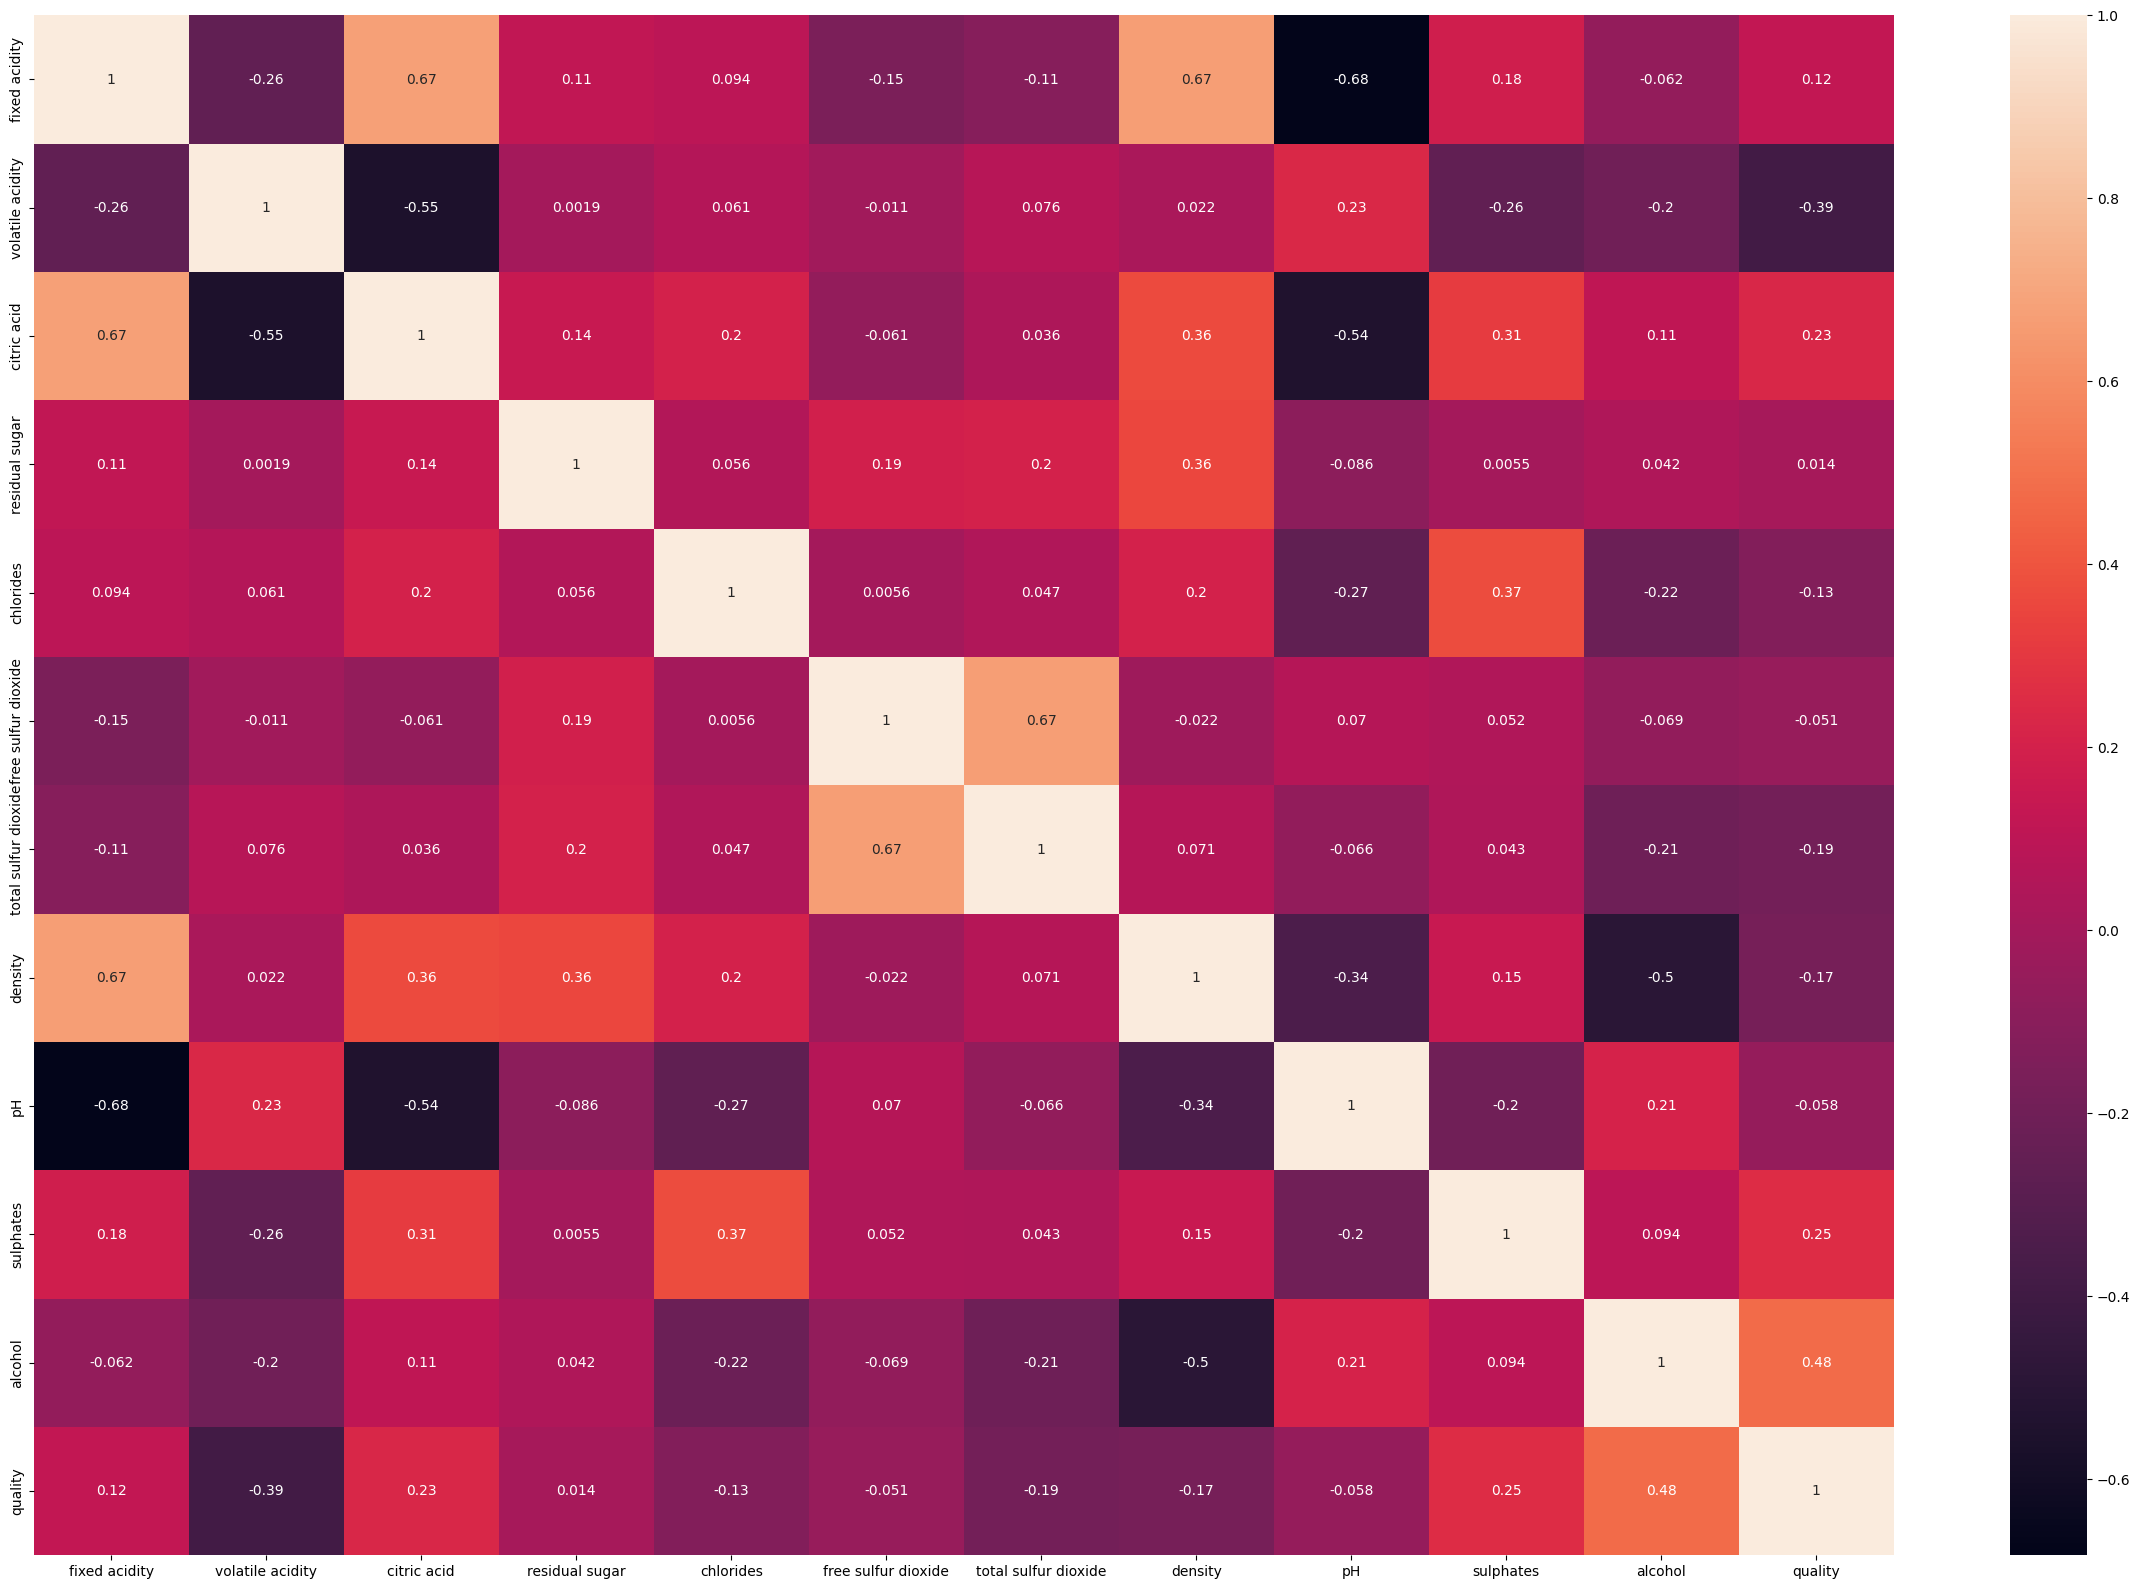

In [11]:
plt.figure(figsize=(30,20))
corr = data.corr()
sns.heatmap(data.corr(),annot=True)
plt.savefig("Correlation Matrix.png")
plt.show()


Detection of outliers using z-score

In [12]:
from scipy import stats
z = np.abs(stats.zscore(data))
print(z)

[[0.52835961 0.96187667 1.39147228 ... 0.57920652 0.96024611 0.78782264]
 [0.29854743 1.96744245 1.39147228 ... 0.1289504  0.58477711 0.78782264]
 [0.29854743 1.29706527 1.18607043 ... 0.04808883 0.58477711 0.78782264]
 ...
 [1.1603431  0.09955388 0.72391627 ... 0.54204194 0.54162988 0.45084835]
 [1.39015528 0.65462046 0.77526673 ... 0.30598963 0.20930812 0.78782264]
 [1.33270223 1.21684919 1.02199944 ... 0.01092425 0.54162988 0.45084835]]


z > 3(threshols) -> this is an outlier

In [13]:
print(np.where(z>3))

(array([  13,   14,   15,   15,   17,   17,   19,   33,   38,   42,   43,
         45,   57,   81,   81,   83,   86,   88,   91,   92,   95,  106,
        106,  109,  120,  126,  127,  142,  144,  147,  151,  151,  151,
        151,  163,  164,  169,  169,  181,  199,  226,  226,  240,  243,
        244,  258,  258,  274,  281,  291,  324,  325,  339,  340,  347,
        354,  374,  381,  391,  396,  396,  400,  400,  442,  442,  451,
        459,  467,  480,  480,  494,  515,  517,  544,  554,  554,  555,
        555,  557,  557,  568,  584,  588,  591,  595,  608,  614,  636,
        639,  649,  649,  651,  652,  652,  652,  672,  672,  684,  690,
        690,  692,  692,  695,  723,  724,  730,  754,  776,  777,  795,
        821,  832,  836,  837,  889,  899,  911,  917,  923,  925,  926,
        982, 1017, 1018, 1043, 1051, 1051, 1071, 1074, 1079, 1079, 1081,
       1081, 1111, 1114, 1131, 1154, 1165, 1175, 1186, 1231, 1235, 1244,
       1244, 1244, 1260, 1269, 1269, 1270, 1270, 1

remove thoses records whoses z>3 outlier

In [16]:
new_data = data[(z < 3).all(axis=1)]

In [17]:
new_data.shape

(1451, 12)

In [18]:
data.shape

(1599, 12)

Data Splitting into feature(x) and target column (y)

In [20]:
from sklearn.model_selection import train_test_split
#X = income
x = new_data.drop('quality',axis=1)
#Y = outcome
y = new_data['quality']

In [21]:
x.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4


In [22]:
y

,quality
0,5
1,5
2,5
3,6
4,5
...,...
1594,5
1595,6
1596,6
1597,5


splitting

In [23]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2)

**Data Modeling using Random Forest Classifier**


In [25]:
from sklearn.ensemble import RandomForestClassifier
rf_classificationModel = RandomForestClassifier(n_estimators=100)


In [26]:
rf_classificationModel.fit(x_train,y_train)

RandomForestClassifier()

**Prediction of data using random forest model**




In [29]:
y_pred = rf_classificationModel.predict(x_test)

In [30]:
y_pred

array([6, 5, 5, 6, 5, 6, 5, 7, 6, 5, 6, 5, 6, 6, 6, 6, 5, 5, 5, 5, 5, 5,
       5, 5, 7, 6, 6, 5, 7, 5, 5, 5, 6, 5, 6, 7, 6, 6, 7, 6, 5, 7, 6, 5,
       6, 5, 5, 5, 5, 7, 6, 6, 6, 7, 5, 5, 6, 7, 6, 5, 5, 6, 6, 5, 5, 5,
       6, 5, 5, 6, 5, 5, 6, 6, 5, 5, 5, 6, 7, 6, 6, 5, 5, 5, 6, 5, 5, 5,
       7, 5, 5, 5, 7, 5, 7, 5, 7, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 5, 5, 7,
       5, 5, 5, 5, 5, 5, 5, 6, 6, 5, 7, 6, 5, 7, 6, 5, 5, 6, 5, 6, 5, 7,
       6, 6, 7, 7, 6, 5, 5, 5, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5,
       6, 5, 6, 5, 5, 6, 5, 5, 7, 5, 6, 5, 5, 7, 5, 5, 5, 5, 5, 5, 5, 5,
       5, 6, 5, 5, 6, 6, 5, 6, 6, 5, 6, 7, 5, 5, 6, 5, 6, 5, 6, 6, 6, 5,
       5, 5, 6, 6, 7, 5, 6, 5, 6, 5, 6, 6, 6, 7, 6, 7, 5, 6, 5, 6, 6, 5,
       5, 5, 5, 5, 6, 6, 5, 5, 5, 5, 6, 5, 5, 6, 6, 6, 6, 5, 7, 6, 6, 6,
       6, 6, 5, 6, 5, 5, 5, 7, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 7,
       6, 6, 6, 5, 6, 5, 5, 5, 5, 5, 6, 6, 6, 6, 5, 5, 5, 6, 5, 6, 6, 6,
       5, 7, 6, 5, 5])

**data evaluation on metrics**

In [34]:
from sklearn import metrics
print ('Accuracy Score ',metrics.accuracy_score(y_test,y_pred))

Accuracy Score  0.6838487972508591


<Figure size 2000x2000 with 0 Axes>

Accuracy Score :68.3%

1. hyperparameter tunning -> GridSearchCV

[Text(0.6890581671288396, 0.9772727272727273, 'x[6] <= 83.0\ngini = 0.645\nsamples = 734\nvalue = [38, 499, 450, 158, 15]'),
 Text(0.4449536493885097, 0.9318181818181818, 'x[1] <= 0.385\ngini = 0.655\nsamples = 647\nvalue = [35, 387, 430, 154, 15]'),
 Text(0.5670059082586747, 0.9545454545454546, 'True  '),
 Text(0.14789533560864618, 0.8863636363636364, 'x[10] <= 10.75\ngini = 0.674\nsamples = 176\nvalue = [6.0, 49.0, 120.0, 101.0, 13.0]'),
 Text(0.0671217292377702, 0.8409090909090909, 'x[1] <= 0.285\ngini = 0.65\nsamples = 71\nvalue = [6, 43, 53, 16, 1]'),
 Text(0.034129692832764506, 0.7954545454545454, 'x[1] <= 0.245\ngini = 0.489\nsamples = 21\nvalue = [3, 7, 26, 2, 0]'),
 Text(0.022753128555176336, 0.75, 'x[5] <= 12.5\ngini = 0.653\nsamples = 6\nvalue = [3, 5, 4, 0, 0]'),
 Text(0.013651877133105802, 0.7045454545454546, 'x[4] <= 0.097\ngini = 0.469\nsamples = 4\nvalue = [0, 5, 3, 0, 0]'),
 Text(0.009101251422070534, 0.6590909090909091, 'x[10] <= 9.55\ngini = 0.278\nsamples = 3\nvalue

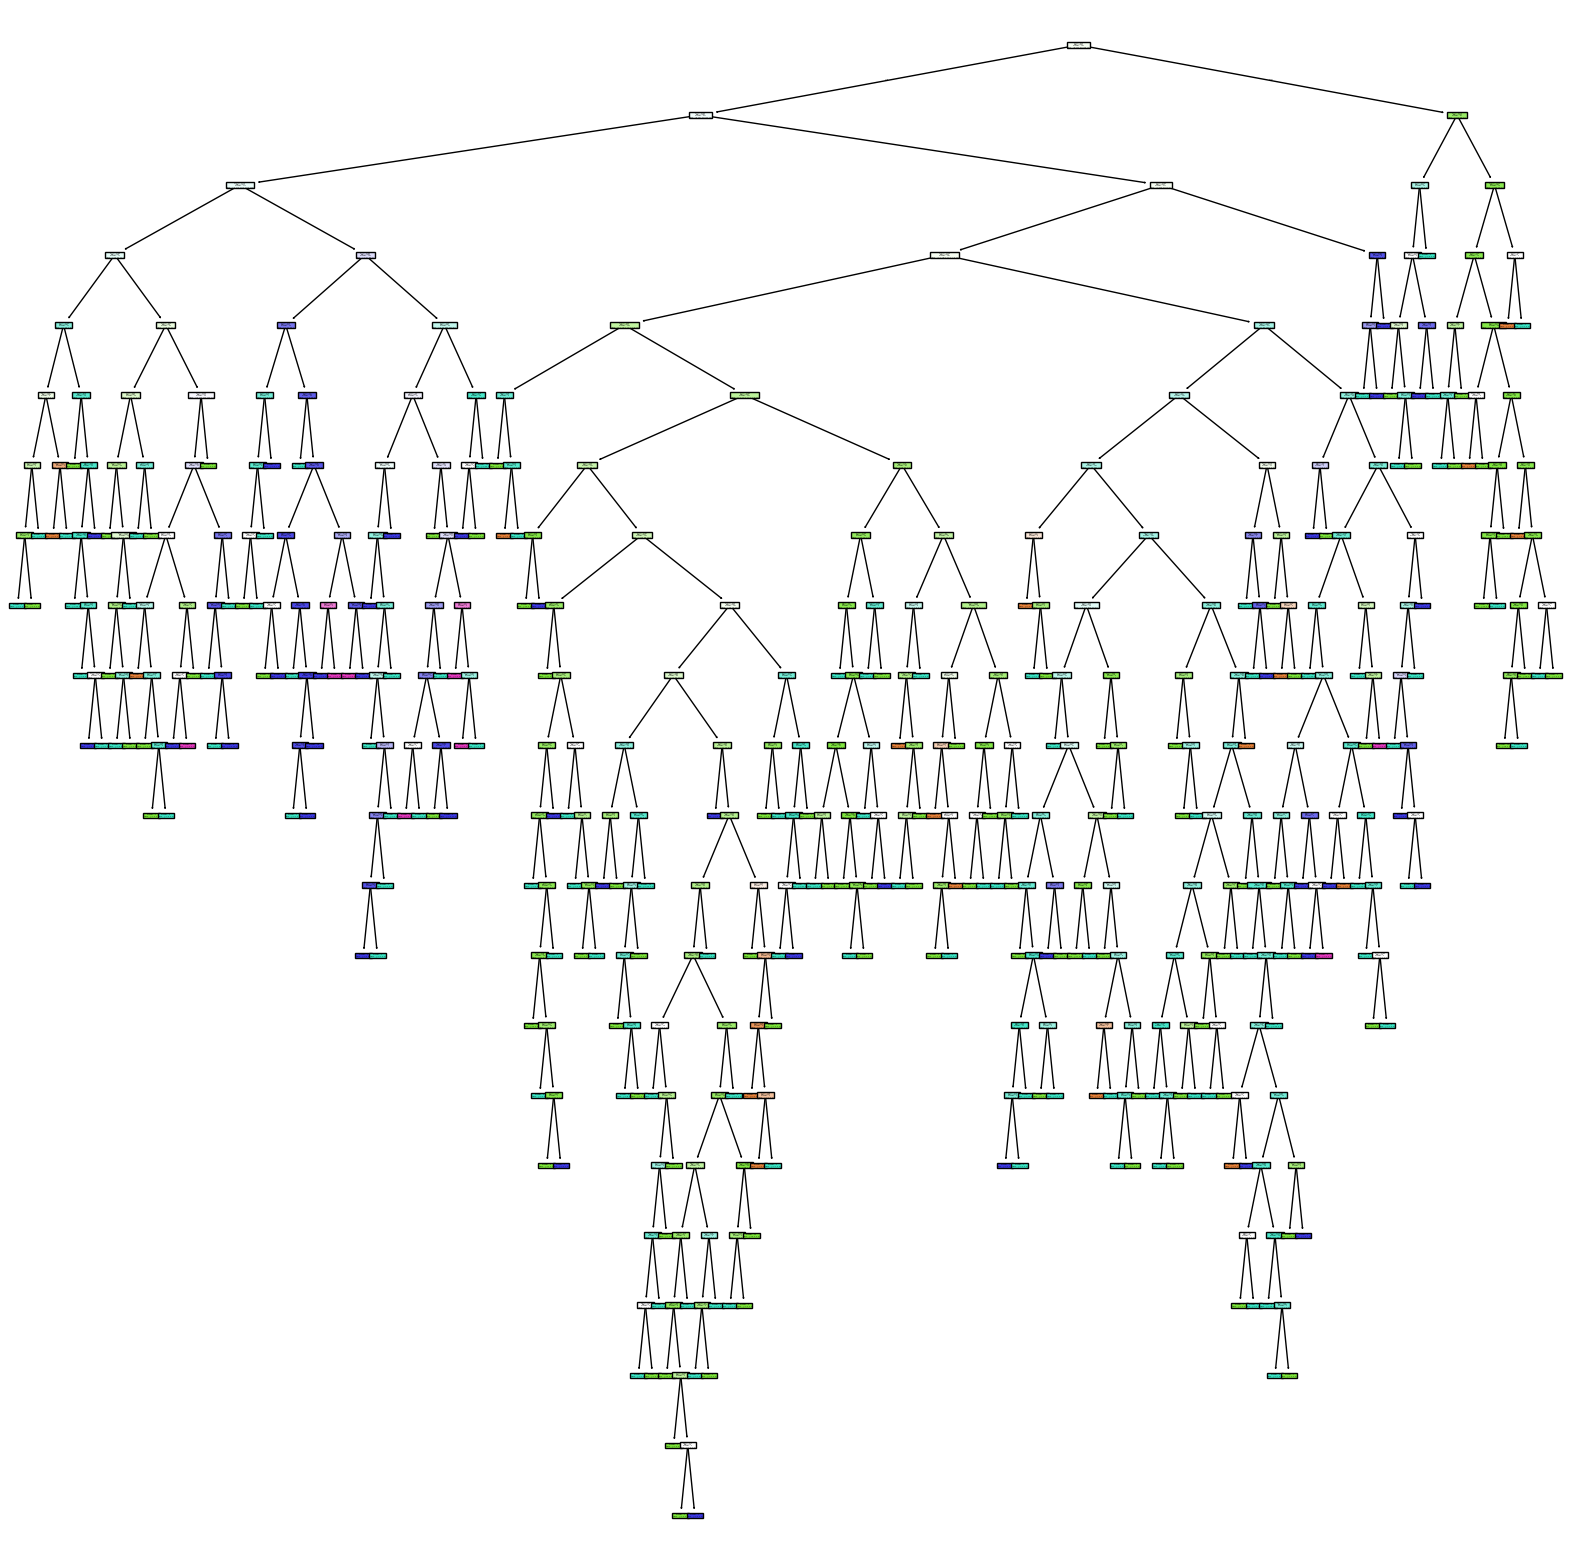

In [35]:
plt.figure(figsize=(20,20))

from sklearn import tree
tree.plot_tree(rf_classificationModel.estimators_[0],filled=True)

KeyboardInterrupt: 

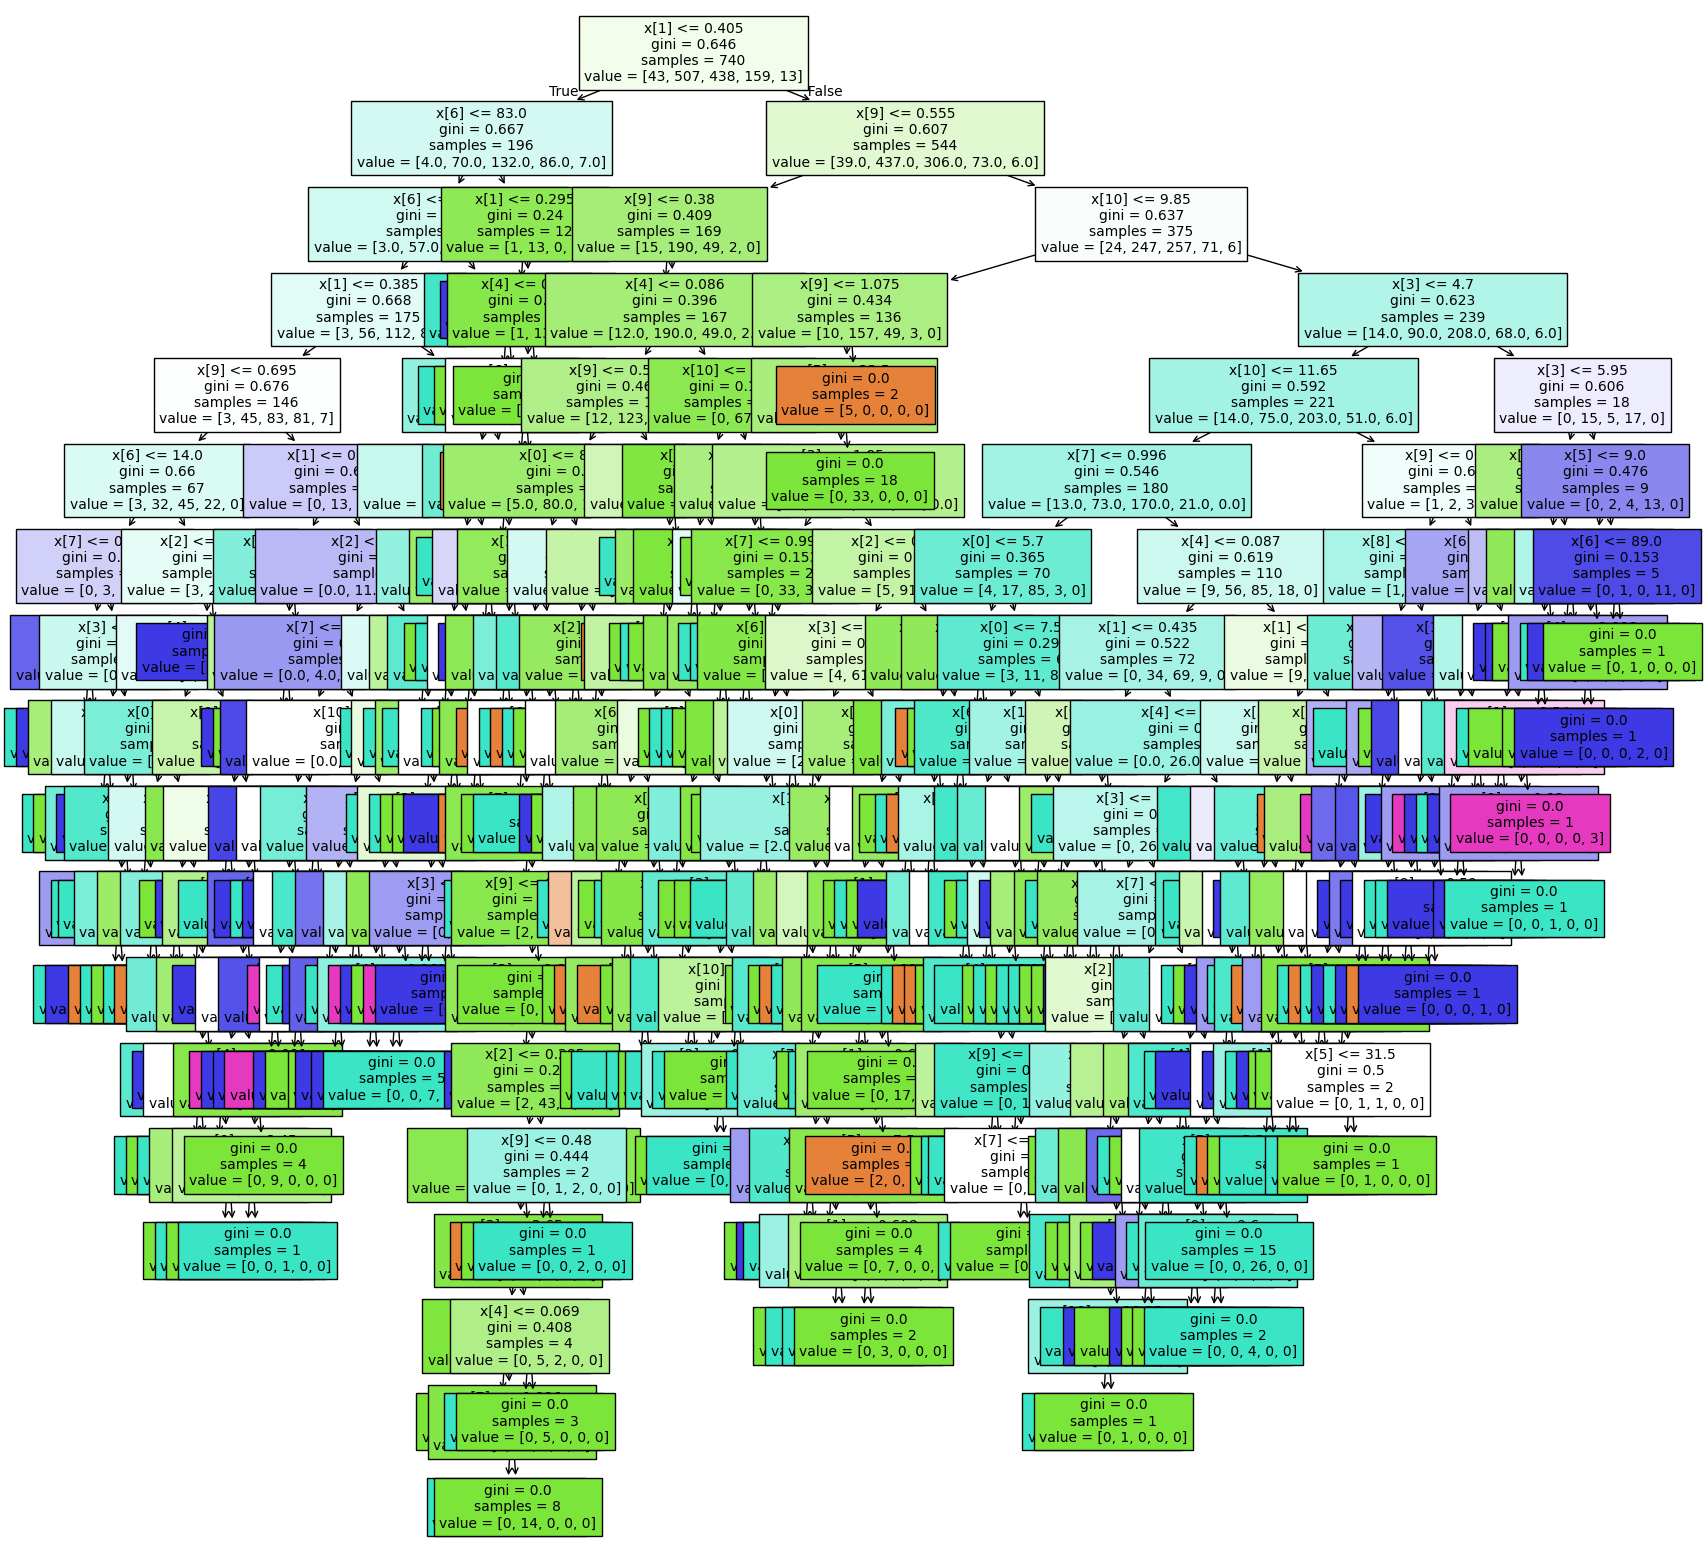

In [36]:
plt.figure(figsize=(20,20))
for i in range(len(rf_classificationModel.estimators_)):
  tree.plot_tree(rf_classificationModel.estimators_[i],filled=True)


### Exporting the Model
We will use `joblib` to export the trained Random Forest model so that it can be used for deployment or future inference without retraining.

In [37]:
import joblib

# Save the model to a file
model_filename = 'rf_wine_quality_model.joblib'
joblib.dump(rf_classificationModel, model_filename)
print(f"Model successfully exported to {model_filename}")

Model successfully exported to rf_wine_quality_model.joblib


### Use Case Demo
Now we will load the saved model and simulate a real-world use case by predicting the quality of a new wine sample.

In [38]:
# Load the model back
loaded_model = joblib.load('rf_wine_quality_model.joblib')

# Create a sample input representing a wine's features
# We will use the first row of our testing set as a mock new sample
sample_wine = x_test.iloc[[0]]

# Predict using the loaded model
predicted_quality = loaded_model.predict(sample_wine)

print("Sample Wine Features:")
display(sample_wine)
print(f"Predicted Wine Quality: {predicted_quality[0]}")
print(f"Actual Wine Quality was: {y_test.iloc[0]}")

Sample Wine Features:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
1528,7.9,0.29,0.49,2.2,0.096,21.0,59.0,0.99714,3.31,0.67,10.1


Predicted Wine Quality: 6
Actual Wine Quality was: 6
